# Motor Insurance Risk Pricing Using Poisson and Gamma GLMs

Frequency–severity pricing analysis on the French motor third-party liability datasets
`freMTPL2freq` and `freMTPL2sev` (CASdatasets). The notebook validates the data, explores
risk factors, fits a Poisson frequency GLM and a Gamma severity GLM, and compares
pure premium estimates on held-out policies.

**Data:** place `freMTPL2freq.csv` and `freMTPL2sev.csv` in `data/raw/` (see README).

## 1. Data Preparation and Validation

In [1]:
from pathlib import Path

import pandas as pd

data_dir = Path("data") / "raw"

freq = pd.read_csv(data_dir / "freMTPL2freq.csv")
sev = pd.read_csv(data_dir / "freMTPL2sev.csv")

print("Frequency (rows, columns):", freq.shape)
print("Frequency columns:", freq.columns.tolist())

print("\nSeverity (rows, columns):", sev.shape)
print("Severity columns:", sev.columns.tolist())

Frequency (rows, columns): (677991, 12)
Frequency columns: ['IDpol', 'ClaimNb', 'Exposure', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'VehBrand', 'VehGas', 'Area', 'Density', 'Region']

Severity (rows, columns): (26444, 2)
Severity columns: ['IDpol', 'ClaimAmount']


In [2]:
print("Frequency data types")
print(freq.dtypes)
display(freq.head(3))

print("\nSeverity data types")
print(sev.dtypes)
display(sev.head(3))


Frequency data types
IDpol         float64
ClaimNb         int64
Exposure      float64
VehPower        int64
VehAge          int64
DrivAge         int64
BonusMalus      int64
VehBrand       object
VehGas         object
Area           object
Density         int64
Region         object
dtype: object


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region
0,1.0,0,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
1,3.0,0,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
2,5.0,0,0.75,6,2,52,50,B12,Diesel,B,54,Picardie



Severity data types
IDpol            int64
ClaimAmount    float64
dtype: object


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11


In [3]:
print("Frequency missing values by column")
print(freq.isna().sum())

print("\nSeverity missing values by column")
print(sev.isna().sum())

freq_ids = freq["IDpol"].dropna()

print("\nNonmissing frequency IDs that are not whole numbers:",
      (freq_ids % 1 != 0).sum())
print("Repeated frequency ID rows beyond the first occurrence:",
      freq_ids.duplicated().sum())


Frequency missing values by column
IDpol         0
ClaimNb       0
Exposure      0
VehPower      0
VehAge        0
DrivAge       0
BonusMalus    0
VehBrand      0
VehGas        0
Area          0
Density       0
Region        0
dtype: int64

Severity missing values by column
IDpol          0
ClaimAmount    0
dtype: int64

Nonmissing frequency IDs that are not whole numbers: 0
Repeated frequency ID rows beyond the first occurrence: 0


In [4]:
freq["IDpol"] = freq["IDpol"].astype("int64")

matched = sev["IDpol"].isin(freq["IDpol"])
severity_counts = sev.loc[matched].groupby("IDpol").size()
recorded_counts = freq["IDpol"].map(severity_counts).fillna(0).astype("int64")

print("Severity rows without a matching policy:", (~matched).sum())
print("Total claims reported in frequency:", freq["ClaimNb"].sum())
print("Total matched severity rows:", matched.sum())
print("Policies with fewer severity rows than reported claims:",
      (recorded_counts < freq["ClaimNb"]).sum())
print("Policies with more severity rows than reported claims:",
      (recorded_counts > freq["ClaimNb"]).sum())

Severity rows without a matching policy: 0
Total claims reported in frequency: 26444
Total matched severity rows: 26444
Policies with fewer severity rows than reported claims: 0
Policies with more severity rows than reported claims: 0


In [5]:
display(freq[["Exposure", "ClaimNb"]].describe())
display(sev[["ClaimAmount"]].describe())

print("Policies with nonpositive exposure:", freq["Exposure"].le(0).sum())
print("Policies with exposure above one year:", freq["Exposure"].gt(1).sum())
print("Policies with negative claim counts:", freq["ClaimNb"].lt(0).sum())
print("Severity rows with nonpositive amounts:", sev["ClaimAmount"].le(0).sum())
print("Identical severity rows beyond the first:", sev.duplicated().sum())


,Exposure,ClaimNb
count,677991.000000,677991.000000
mean,0.528743,0.039003
std,0.364441,0.207169
min,0.002732,0.000000
25%,0.180000,0.000000
50%,0.490000,0.000000
75%,0.990000,0.000000
max,2.010000,16.000000


,ClaimAmount
count,2.644400e+04
mean,2.265513e+03
std,2.937103e+04
min,1.000000e+00
25%,6.859925e+02
50%,1.172000e+03
75%,1.212385e+03
max,4.075401e+06


Policies with nonpositive exposure: 0
Policies with exposure above one year: 1224
Policies with negative claim counts: 0
Severity rows with nonpositive amounts: 0
Identical severity rows beyond the first: 235


In [6]:
long_exposure = freq.loc[freq["Exposure"] > 1]

exposure_share = long_exposure["Exposure"].sum() / freq["Exposure"].sum()
claim_share = long_exposure["ClaimNb"].sum() / freq["ClaimNb"].sum()

print(f"Share of total exposure: {exposure_share:.2%}")
print(f"Share of total claims: {claim_share:.2%}")
display(long_exposure[["Exposure", "ClaimNb"]].describe())

Share of total exposure: 0.38%
Share of total claims: 0.20%


,Exposure,ClaimNb
count,1224.000000,1224.000000
mean,1.113840,0.044118
std,0.159296,0.217052
min,1.010000,0.000000
25%,1.020000,0.000000
50%,1.040000,0.000000
75%,1.150000,0.000000
max,2.010000,2.000000


### Stage 1 Summary

I exported `freMTPL2freq` and `freMTPL2sev` from the original CASdatasets R package and loaded the CSV files into Python. The frequency table contained 677,991 policy records and 12 columns. The severity table contained 26,444 claim records and 2 columns.

I verified that both tables had no missing values and that each policy ID appeared once in the frequency table. I converted the frequency policy IDs to integers after checking that every ID was a whole number. All severity rows matched a policy, and the number of severity rows matched the reported claim count for every policy.

All exposures and claim amounts were positive, and all claim counts were nonnegative. I retained the recorded exposures, including 1,224 policies with more than one year of exposure, which accounted for 0.38% of total exposure. I also retained 235 repeated policy ID and claim amount combinations because the severity file has no claim identifier to distinguish separate claims of the same amount, and removing those rows would break the policy-level reconciliation.

## 2. Exploratory Data Analysis

In [7]:
total_policies = len(freq)
total_exposure = freq["Exposure"].sum()
total_claims = freq["ClaimNb"].sum()

claim_frequency = total_claims / total_exposure

print(f"Number of policies: {total_policies:,}")
print(f"Total exposure: {total_exposure:,.2f} policy-years")
print(f"Total claims: {total_claims:,}")
print(f"Observed frequency: {100 * claim_frequency:.2f} claims per 100 policy-years")

Number of policies: 677,991
Total exposure: 358,482.84 policy-years
Total claims: 26,444
Observed frequency: 7.38 claims per 100 policy-years


In [8]:
total_claim_cost = sev["ClaimAmount"].sum()
mean_severity = total_claim_cost / len(sev)

pure_premium = total_claim_cost / total_exposure
pure_premium_from_components = claim_frequency * mean_severity

print(f"Total recorded claim cost: €{total_claim_cost:,.2f}")
print(f"Mean claim severity: €{mean_severity:,.2f} per claim")
print(f"Observed pure premium: €{pure_premium:,.2f} per policy-year")
print(f"Frequency × severity: €{pure_premium_from_components:,.2f} per policy-year")

Total recorded claim cost: €59,909,216.50
Mean claim severity: €2,265.51 per claim
Observed pure premium: €167.12 per policy-year
Frequency × severity: €167.12 per policy-year


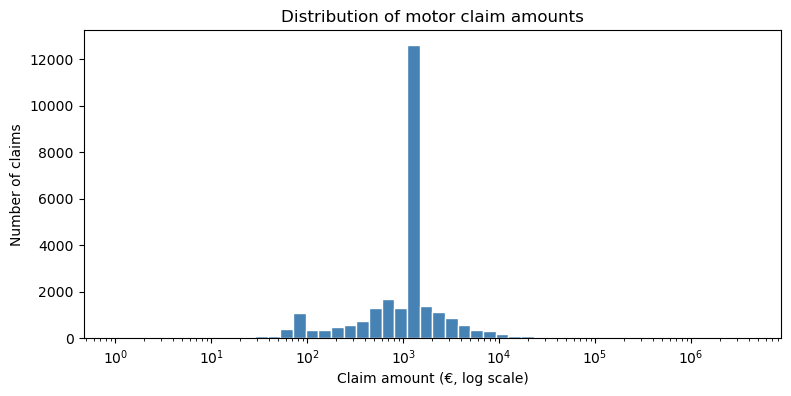

95th percentile: €4,765.09
99th percentile: €16,451.22


In [9]:
import matplotlib.pyplot as plt
import numpy as np

claim_amounts = sev["ClaimAmount"]
bins = np.geomspace(claim_amounts.min(), claim_amounts.max(), 51)
percentiles = claim_amounts.quantile([0.95, 0.99])

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(claim_amounts, bins=bins, color="steelblue", edgecolor="white")
ax.set_xscale("log")
ax.set(
    title="Distribution of motor claim amounts",
    xlabel="Claim amount (€, log scale)",
    ylabel="Number of claims",
)
plt.show()

print(f"95th percentile: €{percentiles.loc[0.95]:,.2f}")
print(f"99th percentile: €{percentiles.loc[0.99]:,.2f}")

In [10]:
p99 = percentiles.loc[0.99]
large_claims = claim_amounts[claim_amounts > p99]
large_claim_cost = large_claims.sum()
largest_claim = claim_amounts.max()

print(f"Claims above the 99th percentile: {len(large_claims):,}")
print(f"Their share of total claim cost: {large_claim_cost / total_claim_cost:.2%}")
print(f"Their contribution per policy-year: €{large_claim_cost / total_exposure:,.2f}")
print(f"Largest claim's share of total claim cost: {largest_claim / total_claim_cost:.2%}")

Claims above the 99th percentile: 265
Their share of total claim cost: 38.01%
Their contribution per policy-year: €63.53
Largest claim's share of total claim cost: 6.80%


,exposure,claims,claims_per_100_policy_years
DrivAge,,,
Under 25,12487.37,2011,16.10
25–34,64597.36,4973,7.70
35–49,131223.17,9563,7.29
50–64,102186.15,7033,6.88
65–74,32205.45,1872,5.81
75+,15783.33,992,6.29


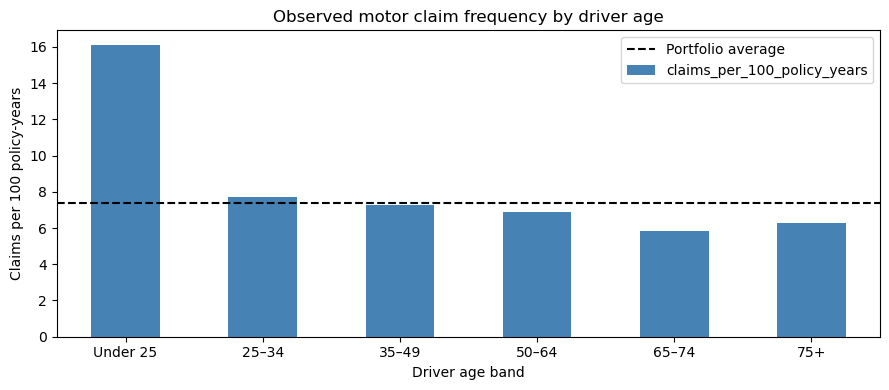

In [11]:
age_band = pd.cut(
    freq["DrivAge"],
    bins=[-np.inf, 25, 35, 50, 65, 75, np.inf],
    labels=["Under 25", "25–34", "35–49", "50–64", "65–74", "75+"],
    right=False,
)

age_summary = freq.groupby(age_band, observed=True).agg(
    exposure=("Exposure", "sum"),
    claims=("ClaimNb", "sum"),
)
age_summary["claims_per_100_policy_years"] = (
    100 * age_summary["claims"] / age_summary["exposure"]
)

display(age_summary.round(2))

ax = age_summary["claims_per_100_policy_years"].plot.bar(
    figsize=(9, 4), color="steelblue", rot=0
)
ax.axhline(
    100 * claim_frequency, color="black", linestyle="--", label="Portfolio average"
)
ax.set(
    title="Observed motor claim frequency by driver age",
    xlabel="Driver age band",
    ylabel="Claims per 100 policy-years",
)
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
bonus_malus_band = pd.cut(
    freq["BonusMalus"],
    bins=[-np.inf, 60, 80, 100, 101, 121, np.inf],
    labels=["Below 60", "60–79", "80–99", "100", "101–120", "121+"],
    right=False,
)

bonus_malus_summary = freq.groupby(bonus_malus_band, observed=True).agg(
    exposure=("Exposure", "sum"),
    claims=("ClaimNb", "sum"),
)
bonus_malus_summary["claims_per_100_policy_years"] = (
    100 * bonus_malus_summary["claims"] / bonus_malus_summary["exposure"]
)

display(bonus_malus_summary.round(2))


,exposure,claims,claims_per_100_policy_years
BonusMalus,,,
Below 60,265051.74,14626,5.52
60–79,53803.92,5750,10.69
80–99,29814.98,3492,11.71
100,6240.87,1320,21.15
101–120,2573.00,800,31.09
121+,998.32,456,45.68


In [13]:
vehicle_age_band = pd.cut(
    freq["VehAge"],
    bins=[0, 2, 6, 11, 16, np.inf],
    labels=["0–1", "2–5", "6–10", "11–15", "16+"],
    right=False,
)

for label, groups in [
    ("Vehicle age band", vehicle_age_band),
    ("Vehicle power level", freq["VehPower"]),
]:
    summary = freq.groupby(groups, observed=True).agg(
        exposure=("Exposure", "sum"),
        claims=("ClaimNb", "sum"),
    )
    summary["claims_per_100_policy_years"] = (
        100 * summary["claims"] / summary["exposure"]
    )
    print(label)
    display(summary.round(2))

Vehicle age band


,exposure,claims,claims_per_100_policy_years
VehAge,,,
0–1,49465.21,3509,7.09
2–5,101744.05,7582,7.45
6–10,99003.24,8009,8.09
11–15,77988.00,5680,7.28
16+,30282.34,1664,5.49


Vehicle power level


,exposure,claims,claims_per_100_policy_years
VehPower,,,
4,60069.71,4003,6.66
5,68168.82,5115,7.50
6,82520.44,6305,7.64
7,77948.44,5593,7.18
8,22682.95,1645,7.25
9,15348.11,1220,7.95
10,15374.42,1217,7.92
11,8497.78,714,8.40
12,3792.04,296,7.81


In [14]:
for column in ["Area", "Region"]:
    geography_summary = freq.groupby(column).agg(
        exposure=("Exposure", "sum"),
        claims=("ClaimNb", "sum"),
    )
    geography_summary["claims_per_100_policy_years"] = (
        100 * geography_summary["claims"] / geography_summary["exposure"]
    )

    if column == "Region":
        geography_summary = geography_summary.sort_values(
            "claims_per_100_policy_years", ascending=False
        )

    print(f"\nClaim frequency by {column}")
    display(geography_summary.round(2))


Claim frequency by Area


,exposure,claims,claims_per_100_policy_years
Area,,,
A,61966.14,3364,5.43
B,43010.75,2633,6.12
C,104443.16,7093,6.79
D,77116.92,6458,8.37
E,63817.10,6122,9.59
F,8128.75,774,9.52



Claim frequency by Region


,exposure,claims,claims_per_100_policy_years
Region,,,
Rhone-Alpes,45343.55,4233,9.34
Picardie,3574.41,314,8.78
Ile-de-France,30207.16,2591,8.58
Provence-Alpes-Cotes-D'Azur,35790.32,2986,8.34
Limousin,2395.99,197,8.22
Nord-Pas-de-Calais,11496.97,944,8.21
Alsace,1209.12,92,7.61
Corse,1765.94,132,7.47
Aquitaine,14322.17,1055,7.37


The portfolio recorded 7.38 claims per 100 policy-years, a mean claim severity of €2,265.51, and an observed pure premium of €167.12 per policy-year. Claim frequency varied across driver age, Bonus–Malus, vehicle characteristics, and geography. Claims above the 99th percentile accounted for 38.01% of recorded claim costs, making the upper tail important when evaluating severity predictions and aggregate claims cost.

## 3. Claim Frequency Model (Poisson GLM)

In [15]:
from sklearn.model_selection import train_test_split

freq_train, freq_test = train_test_split(
    freq,
    test_size=0.20,
    random_state=42,
)

train_policy_ids = freq_train["IDpol"]
test_policy_ids = freq_test["IDpol"]

for name, data in [("Training", freq_train), ("Test", freq_test)]:
    exposure = data["Exposure"].sum()
    claims = data["ClaimNb"].sum()
    rate = 100 * claims / exposure

    print(
        f"{name}: {len(data):,} policies, {exposure:,.2f} policy-years, "
        f"{claims:,} claims, {rate:.2f} claims per 100 policy-years"
    )

print(f"Policies in both sets: {train_policy_ids.isin(test_policy_ids).sum():,}")

Training: 542,392 policies, 286,705.43 policy-years, 21,209 claims, 7.40 claims per 100 policy-years
Test: 135,599 policies, 71,777.41 policy-years, 5,235 claims, 7.29 claims per 100 policy-years
Policies in both sets: 0


In [16]:
frequency_formula = (
    "ClaimNb ~ C(driver_age_band) + C(bonus_malus_band) "
    "+ C(vehicle_age_band) + C(VehPower) + C(Area) + C(Region)"
)

freq_train_model = freq_train.assign(
    driver_age_band=age_band.loc[freq_train.index],
    bonus_malus_band=bonus_malus_band.loc[freq_train.index],
    vehicle_age_band=vehicle_age_band.loc[freq_train.index],
)

train_offset = np.log(freq_train_model["Exposure"])

print(frequency_formula)
display(train_offset.describe().round(3))

ClaimNb ~ C(driver_age_band) + C(bonus_malus_band) + C(vehicle_age_band) + C(VehPower) + C(Area) + C(Region)


count    542392.000
mean         -1.078
std           1.165
min          -5.903
25%          -1.772
50%          -0.713
75%          -0.010
max           0.698
Name: Exposure, dtype: float64

In [17]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

frequency_model = smf.glm(
    formula=frequency_formula,
    data=freq_train_model,
    family=sm.families.Poisson(),
    offset=train_offset,
    missing="raise",
).fit()

print(f"Converged: {frequency_model.converged}")
print(f"Training policies used: {int(frequency_model.nobs):,}")
print(f"Fitted coefficients: {len(frequency_model.params)}")

Converged: True
Training policies used: 542,392
Fitted coefficients: 52


In [18]:
age_coefficients = frequency_model.params.filter(like="C(driver_age_band)")
age_intervals = frequency_model.conf_int().loc[age_coefficients.index]

age_rate_ratios = pd.DataFrame({
    "rate_ratio": np.exp(age_coefficients),
    "95% CI lower": np.exp(age_intervals[0]),
    "95% CI upper": np.exp(age_intervals[1]),
})

print("Reference band: Under 25 (rate ratio = 1.00)")
display(age_rate_ratios.round(3))

Reference band: Under 25 (rate ratio = 1.00)


,rate_ratio,95% CI lower,95% CI upper
C(driver_age_band)[T.25–34],0.724,0.681,0.770
C(driver_age_band)[T.35–49],1.024,0.963,1.088
C(driver_age_band)[T.50–64],1.062,0.996,1.132
C(driver_age_band)[T.65–74],0.945,0.874,1.022
C(driver_age_band)[T.75+],1.035,0.944,1.134


In [19]:
freq_test_model = freq_test.assign(
    driver_age_band=age_band.loc[freq_test.index],
    bonus_malus_band=bonus_malus_band.loc[freq_test.index],
    vehicle_age_band=vehicle_age_band.loc[freq_test.index],
)

test_offset = np.log(freq_test_model["Exposure"])
predicted_claims = frequency_model.predict(freq_test_model, offset=test_offset)

observed_total = freq_test_model["ClaimNb"].sum()
predicted_total = predicted_claims.sum()

print(f"Test policies scored: {predicted_claims.notna().sum():,}")
print(f"Observed claims: {observed_total:,}")
print(f"Predicted claims: {predicted_total:,.2f}")
print(f"Prediction error relative to observed: {predicted_total / observed_total - 1:+.2%}")

Test policies scored: 135,599
Observed claims: 5,235
Predicted claims: 5,318.41
Prediction error relative to observed: +1.59%


In [20]:
frequency_check = freq_test_model[["Exposure", "ClaimNb"]].assign(
    predicted_claims=predicted_claims,
    predicted_annual_rate=predicted_claims / freq_test_model["Exposure"],
)
frequency_check["risk_decile"] = (
    pd.qcut(frequency_check["predicted_annual_rate"], q=10, labels=False) + 1
)

decile_summary = frequency_check.groupby("risk_decile").agg(
    exposure=("Exposure", "sum"),
    observed_claims=("ClaimNb", "sum"),
    predicted_claims=("predicted_claims", "sum"),
)
decile_summary["observed_per_100"] = (
    100 * decile_summary["observed_claims"] / decile_summary["exposure"]
)
decile_summary["predicted_per_100"] = (
    100 * decile_summary["predicted_claims"] / decile_summary["exposure"]
)

display(decile_summary.round(2))

,exposure,observed_claims,predicted_claims,observed_per_100,predicted_per_100
risk_decile,,,,,
1,8172.97,288,299.96,3.52,3.67
2,8198.89,347,374.43,4.23,4.57
3,8092.33,411,410.91,5.08,5.08
4,7823.57,413,433.12,5.28,5.54
5,7378.27,469,444.72,6.36,6.03
6,7190.39,488,474.37,6.79,6.60
7,7070.73,555,522.33,7.85,7.39
8,6317.07,563,568.67,8.91,9.00
9,5937.46,662,697.76,11.15,11.75


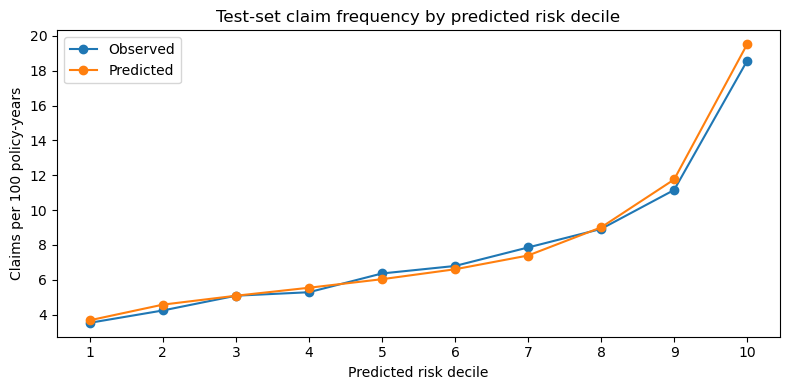

Training Pearson dispersion: 1.838


In [21]:
ax = decile_summary[["observed_per_100", "predicted_per_100"]].rename(
    columns={"observed_per_100": "Observed", "predicted_per_100": "Predicted"}
).plot(marker="o", figsize=(8, 4))

ax.set(
    title="Test-set claim frequency by predicted risk decile",
    xlabel="Predicted risk decile",
    ylabel="Claims per 100 policy-years",
    xticks=decile_summary.index,
)
plt.tight_layout()
plt.show()

pearson_dispersion = frequency_model.pearson_chi2 / frequency_model.df_resid
print(f"Training Pearson dispersion: {pearson_dispersion:.3f}")

In [22]:
quasi_poisson_model = smf.glm(
    formula=frequency_formula,
    data=freq_train_model,
    family=sm.families.Poisson(),
    offset=train_offset,
    missing="raise",
).fit(scale="X2")

age_terms = quasi_poisson_model.params.filter(like="C(driver_age_band)").index
quasi_age_intervals = np.exp(quasi_poisson_model.conf_int().loc[age_terms])
quasi_age_intervals.columns = ["95% CI lower", "95% CI upper"]
quasi_age_intervals.insert(
    0, "rate_ratio", np.exp(quasi_poisson_model.params.loc[age_terms])
)

print(f"Estimated dispersion: {quasi_poisson_model.scale:.3f}")
display(quasi_age_intervals.round(3))

Estimated dispersion: 1.838


,rate_ratio,95% CI lower,95% CI upper
C(driver_age_band)[T.25–34],0.724,0.667,0.787
C(driver_age_band)[T.35–49],1.024,0.942,1.112
C(driver_age_band)[T.50–64],1.062,0.974,1.159
C(driver_age_band)[T.65–74],0.945,0.850,1.051
C(driver_age_band)[T.75+],1.035,0.914,1.172


### Summary — Poisson Frequency Model

I fitted a Poisson GLM with a log link to 542,392 training policies. The model used driver age, Bonus–Malus, vehicle age, vehicle power, area, and region as categorical predictors. I included log exposure as an offset to account for each policy’s observed coverage period.

On 135,599 held-out policies, the model predicted 5,318.41 claims versus 5,235 observed, an overprediction of 1.59%. Observed frequency increased across all ten predicted risk deciles, from 3.52 to 18.57 claims per 100 policy-years. The largest calibration gap occurred in the highest decile, where the model predicted 19.52 claims per 100 policy-years against 18.57 observed.

The training Pearson dispersion statistic of 1.838 indicated overdispersion. I used a quasi-Poisson adjustment to widen the coefficient confidence intervals while retaining the fitted claim rates. Holding the other predictors fixed, drivers aged 25–34 had an estimated annual claim rate 27.6% lower than drivers under 25, with an adjusted rate ratio of 0.724 and a 95% confidence interval of 0.667–0.787. The adjusted intervals for the other age bands all included 1.00.

## 4. Claim Severity Model (Gamma GLM)

In [23]:
claim_in_train = sev["IDpol"].isin(train_policy_ids)
claim_in_test = sev["IDpol"].isin(test_policy_ids)

sev_train = sev.loc[claim_in_train].copy()
sev_test = sev.loc[claim_in_test].copy()

print(f"Training claim rows: {len(sev_train):,}")
print(f"Test claim rows: {len(sev_test):,}")
print(f"Claim rows in both sets: {(claim_in_train & claim_in_test).sum():,}")
print(f"Unassigned claim rows: {(~claim_in_train & ~claim_in_test).sum():,}")

Training claim rows: 21,209
Test claim rows: 5,235
Claim rows in both sets: 0
Unassigned claim rows: 0


In [24]:
severity_predictors = [
    "driver_age_band", "bonus_malus_band", "vehicle_age_band",
    "VehPower", "Area", "Region",
]
policy_columns = ["IDpol", *severity_predictors]

sev_train_model = sev_train.merge(
    freq_train_model[policy_columns],
    on="IDpol", how="left", validate="many_to_one",
)
sev_test_model = sev_test.merge(
    freq_test_model[policy_columns],
    on="IDpol", how="left", validate="many_to_one",
)

for label, data in [("Training", sev_train_model), ("Test", sev_test_model)]:
    missing = data[severity_predictors].isna().any(axis=1).sum()
    print(f"{label}: {len(data):,} claim rows, {missing:,} with missing predictors")

Training: 21,209 claim rows, 0 with missing predictors
Test: 5,235 claim rows, 0 with missing predictors


In [25]:
severity_formula = frequency_formula.replace("ClaimNb", "ClaimAmount", 1)

severity_model = smf.glm(
    formula=severity_formula,
    data=sev_train_model,
    family=sm.families.Gamma(link=sm.families.links.Log()),
    missing="raise",
).fit()

print(f"Converged: {severity_model.converged}")
print(f"Training claims used: {int(severity_model.nobs):,}")
print(f"Fitted coefficients: {len(severity_model.params)}")

Converged: True
Training claims used: 21,209
Fitted coefficients: 52


In [26]:
from sklearn.metrics import mean_gamma_deviance

observed_severity = sev_test_model["ClaimAmount"]
predicted_severity = severity_model.predict(sev_test_model)

baseline_severity = np.full(
    len(sev_test_model), sev_train_model["ClaimAmount"].mean()
)

observed_cost = observed_severity.sum()
predicted_cost = predicted_severity.sum()

print(f"Test claims scored: {predicted_severity.notna().sum():,}")
print(f"Observed mean severity: €{observed_severity.mean():,.2f}")
print(f"Predicted mean severity: €{predicted_severity.mean():,.2f}")
print(f"Total cost error: {predicted_cost / observed_cost - 1:+.2%}")
print(f"Gamma GLM mean deviance: {mean_gamma_deviance(observed_severity, predicted_severity):.4f}")
print(f"Baseline mean deviance: {mean_gamma_deviance(observed_severity, baseline_severity):.4f}")

Test claims scored: 5,235
Observed mean severity: €2,073.91
Predicted mean severity: €2,203.10
Total cost error: +6.23%
Gamma GLM mean deviance: 1.6957
Baseline mean deviance: 1.6099


,claims,observed_mean,predicted_mean
severity_decile,,,
1,525,1463.83,1307.70
2,522,3294.25,1513.86
3,525,1912.95,1645.18
4,523,1667.38,1759.80
5,523,1879.62,1866.12
6,524,1686.07,1994.65
7,522,1668.12,2128.83
8,524,3077.45,2307.37
9,523,1956.18,2674.16


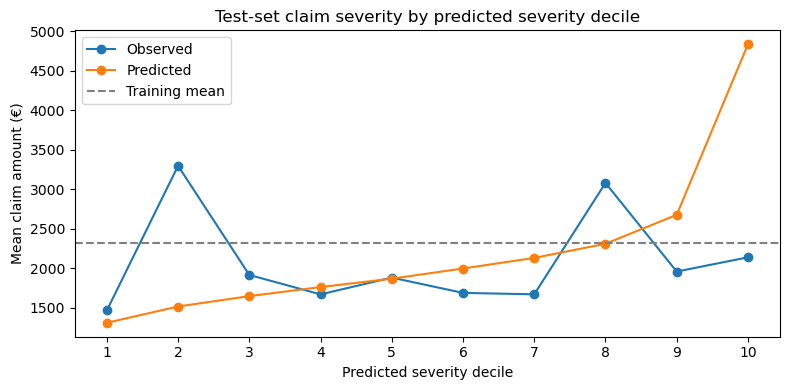

In [27]:
severity_check = pd.DataFrame({
    "observed": observed_severity,
    "predicted": predicted_severity,
})
severity_check["severity_decile"] = (
    pd.qcut(severity_check["predicted"], q=10, labels=False) + 1
)

severity_summary = severity_check.groupby("severity_decile").agg(
    claims=("observed", "size"),
    observed_mean=("observed", "mean"),
    predicted_mean=("predicted", "mean"),
)
display(severity_summary.round(2))

ax = severity_summary[["observed_mean", "predicted_mean"]].rename(
    columns={"observed_mean": "Observed", "predicted_mean": "Predicted"}
).plot(marker="o", figsize=(8, 4))

ax.axhline(
    baseline_severity[0], color="gray", linestyle="--", label="Training mean"
)
ax.set(
    title="Test-set claim severity by predicted severity decile",
    xlabel="Predicted severity decile",
    ylabel="Mean claim amount (€)",
    xticks=severity_summary.index,
)
ax.legend()
plt.tight_layout()
plt.show()

### Summary: Gamma Severity Model

I fitted a Gamma GLM with a log link to 21,209 individual claims and evaluated it on 5,235 held-out claims. I reused the policy-level split from the frequency model so that all claims from a policy stayed in the same set.

The model predicted a mean severity of €2,203.10 per claim versus €2,073.91 observed, an aggregate overprediction of 6.23%. Its mean Gamma deviance was 1.6957, compared with 1.6099 for a constant model based on the training mean. Observed mean severity did not increase consistently across predicted deciles, and the largest overprediction occurred in the highest predicted decile.

On this test split, the constant baseline performed better on Gamma deviance. I will carry both severity estimates into the pure premium evaluation to check whether the Gamma model improves combined claim-cost predictions.

## 5. Pure Premium: Frequency × Severity

In [28]:
pricing_test = freq_test_model[["IDpol", "Exposure"]].copy()

pricing_test["annual_claim_rate"] = predicted_claims / pricing_test["Exposure"]
pricing_test["gamma_severity"] = severity_model.predict(freq_test_model)
constant_severity = sev_train_model["ClaimAmount"].mean()

pricing_test["annual_pure_premium_gamma"] = (
    pricing_test["annual_claim_rate"] * pricing_test["gamma_severity"]
)
pricing_test["annual_pure_premium_constant"] = (
    pricing_test["annual_claim_rate"] * constant_severity
)

for approach in ["gamma", "constant"]:
    annual_premium = pricing_test[f"annual_pure_premium_{approach}"]
    pricing_test[f"expected_cost_{approach}"] = annual_premium * pricing_test["Exposure"]

print(f"Test policies scored by both approaches: "
      f"{pricing_test[['expected_cost_gamma', 'expected_cost_constant']].dropna().shape[0]:,}")
print(f"Constant severity: €{constant_severity:,.2f} per claim")
display(pricing_test.head().round(4))

Test policies scored by both approaches: 135,599
Constant severity: €2,312.81 per claim


,IDpol,Exposure,annual_claim_rate,gamma_severity,annual_pure_premium_gamma,annual_pure_premium_constant,expected_cost_gamma,expected_cost_constant
202518,2006522,0.45,0.1494,2034.0182,303.9092,345.5637,136.7591,155.5037
207934,2016575,0.63,0.0823,3325.5552,273.7258,190.3666,172.4473,119.9310
228661,2064684,0.23,0.0684,1657.7396,113.3609,158.1562,26.0730,36.3759
653232,6052655,0.29,0.0599,2343.0319,140.3630,138.5523,40.7053,40.1802
539417,4130614,1.00,0.0538,2439.1394,131.3305,124.5283,131.3305,124.5283


In [29]:
test_exposure = pricing_test["Exposure"].sum()
actual_test_cost = sev_test["ClaimAmount"].sum()

pricing_summary = pd.DataFrame(
    {
        "total_cost": [
            actual_test_cost,
            pricing_test["expected_cost_gamma"].sum(),
            pricing_test["expected_cost_constant"].sum(),
        ]
    },
    index=["Observed", "Poisson + Gamma", "Poisson + constant severity"],
)

pricing_summary["cost_per_policy_year"] = (
    pricing_summary["total_cost"] / test_exposure
)
pricing_summary["error_pct"] = (
    100 * (pricing_summary["total_cost"] / actual_test_cost - 1)
)

display(pricing_summary.round(2))

,total_cost,cost_per_policy_year,error_pct
Observed,10856912.52,151.26,0.00
Poisson + Gamma,11738093.91,163.53,8.12
Poisson + constant severity,12300456.11,171.37,13.30


,observed,gamma,constant
risk_decile,,,
1,48.23,76.37,84.88
2,106.59,96.63,105.62
3,77.91,104.29,117.44
4,80.58,109.36,128.04
5,106.83,115.75,139.40
6,170.27,128.37,152.58
7,164.06,143.35,170.85
8,158.84,173.92,208.20
9,181.35,245.70,271.80


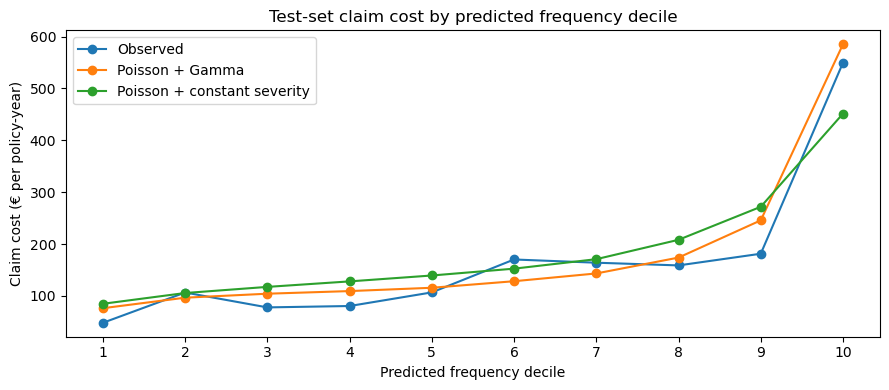

In [30]:
actual_cost_by_policy = sev_test.groupby("IDpol")["ClaimAmount"].sum()

pricing_by_risk = pricing_test.assign(
    risk_decile=frequency_check["risk_decile"],
    observed_cost=pricing_test["IDpol"].map(actual_cost_by_policy).fillna(0),
)

risk_cost_summary = pricing_by_risk.groupby("risk_decile").agg(
    exposure=("Exposure", "sum"),
    observed=("observed_cost", "sum"),
    gamma=("expected_cost_gamma", "sum"),
    constant=("expected_cost_constant", "sum"),
)

cost_columns = ["observed", "gamma", "constant"]
cost_per_year = risk_cost_summary[cost_columns].div(
    risk_cost_summary["exposure"], axis="index"
)
display(cost_per_year.round(2))

ax = cost_per_year.rename(columns={
    "observed": "Observed",
    "gamma": "Poisson + Gamma",
    "constant": "Poisson + constant severity",
}).plot(marker="o", figsize=(9, 4))

ax.set(
    title="Test-set claim cost by predicted frequency decile",
    xlabel="Predicted frequency decile",
    ylabel="Claim cost (€ per policy-year)",
    xticks=cost_per_year.index,
)
plt.tight_layout()
plt.show()

In [31]:
from sklearn.metrics import mean_tweedie_deviance

train_cost_by_policy = sev_train.groupby("IDpol")["ClaimAmount"].sum()
tweedie_train = freq_train_model.assign(
    observed_cost=freq_train_model["IDpol"].map(train_cost_by_policy).fillna(0)
)
tweedie_train["observed_pure_premium"] = (
    tweedie_train["observed_cost"] / tweedie_train["Exposure"]
)

tweedie_power = 1.5
tweedie_model = smf.glm(
    formula=frequency_formula.replace("ClaimNb", "observed_pure_premium", 1),
    data=tweedie_train,
    family=sm.families.Tweedie(
        var_power=tweedie_power, link=sm.families.links.Log()
    ),
    var_weights=tweedie_train["Exposure"],
    missing="raise",
).fit()

test_observed_rate = pricing_by_risk["observed_cost"] / pricing_test["Exposure"]
predicted_rates = {
    "Poisson + Gamma": pricing_test["annual_pure_premium_gamma"],
    "Poisson + constant severity": pricing_test["annual_pure_premium_constant"],
    "Tweedie": tweedie_model.predict(freq_test_model),
}

comparison = []
for name, annual_rate in predicted_rates.items():
    predicted_cost = (annual_rate * pricing_test["Exposure"]).sum()
    comparison.append({
        "model": name,
        "euros_per_policy_year": predicted_cost / test_exposure,
        "portfolio_error_pct": 100 * (predicted_cost / actual_test_cost - 1),
        "mean_tweedie_deviance": mean_tweedie_deviance(
            test_observed_rate,
            annual_rate,
            sample_weight=pricing_test["Exposure"],
            power=tweedie_power,
        ),
    })

print(f"Tweedie converged: {tweedie_model.converged}")
display(pd.DataFrame(comparison).set_index("model").round(4))

Tweedie converged: True


,euros_per_policy_year,portfolio_error_pct,mean_tweedie_deviance
model,,,
Poisson + Gamma,163.5347,8.1163,78.3873
Poisson + constant severity,171.3695,13.2961,77.8090
Tweedie,167.4487,10.7040,78.6685


### Summary: Pure Premium Model Comparison

I compared three approaches on the same 135,599 held-out policies. The two-part approaches combined Poisson claim frequency with either Gamma severity or the constant training mean severity. The direct Tweedie GLM estimated pure premium from recorded claim cost per policy-year, using exposure weights and a fixed variance power of 1.5.

Observed claims cost was €151.26 per policy-year.

| Model | Predicted cost per policy-year | Portfolio error | Exposure-weighted mean Tweedie deviance |
| --- | ---: | ---: | ---: |
| Poisson + Gamma | €163.53 | +8.12% | 78.3873 |
| Poisson + constant severity | €171.37 | +13.30% | 77.8090 |
| Direct Tweedie | €167.45 | +10.70% | 78.6685 |

Poisson + Gamma came closest to the observed portfolio total. It also came closer than Poisson + constant severity in seven of ten predicted frequency deciles. Poisson + constant severity had the lowest policy-level Tweedie deviance. The direct Tweedie model had intermediate portfolio error and the highest deviance. The Tweedie comparison was exploratory because I added it after reviewing results from the same test split.

## 6. Business Interpretation

### Claim frequency for portfolio segmentation

The Poisson model separated lower-frequency from higher-frequency groups in the held-out sample. The highest predicted frequency decile recorded 18.57 claims per 100 policy-years, more than five times the lowest decile’s 3.52. A pricing team could use this ranking to prioritise segments for review and monitor observed versus expected claim frequency.

Driver age illustrates why adjustment matters. After accounting for the other predictors and adjusting the confidence intervals for overdispersion, drivers aged 25–34 had an estimated annual claim rate 27.6% lower than drivers under 25. The remaining age-band comparisons were less conclusive because their adjusted confidence intervals included a rate ratio of 1.00.

### Model choice depends on the pricing objective

For portfolio budgeting, Poisson + Gamma gave the closest estimate of total claims cost on this split. Its estimate was still 8.12% above observed. It also came closer in the highest-frequency decile, where observed cost was €549.57 per policy-year. Poisson + Gamma predicted €585.09, while Poisson + constant severity predicted €451.39.

For policy-level prediction, Poisson + constant severity achieved the lowest exposure-weighted Tweedie deviance. The constant severity baseline also scored better than the Gamma GLM on claim-level Gamma deviance in Stage 4. The direct Tweedie model provided a single estimate of pure premium, but neither of the two evaluation metrics ranked it first.

### Validation before commercial use

Claims above the 99th percentile accounted for 38.01% of recorded costs in the full dataset. A few large losses can therefore shift observed severity and pure premium materially. The comparison used one random split of a historical French motor portfolio, and the test set had already been reviewed before I added Tweedie. Before choosing a model for Dutch pricing, I would compare the approaches on recent Dutch data using an out-of-time validation period and check how sensitive the results are to large losses.

The models estimate expected claims cost. A commercial premium would also reflect expenses, reinsurance costs, and a target profit margin.